In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"

DATA_PATH = PROCESSED_PATH / "electricity_15min_cleaned.csv"

df = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (136615, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:30:00,4.140667,0.327733,234.768667,17.773333,0.0,0.733333,16.866667
2006-12-16 17:45:00,4.159333,0.028267,234.630000,17.786667,0.0,0.000000,16.866667
2006-12-16 18:00:00,4.121067,0.152533,235.566000,17.706667,0.0,19.933333,17.000000
2006-12-16 18:15:00,3.768533,0.017200,234.803333,16.226667,0.0,2.866667,16.933333
2006-12-16 18:30:00,3.127600,0.056533,234.582667,13.440000,0.0,2.666667,16.866667


In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate timestamps:", df.index.duplicated().sum())
print("Time gaps:", (df.index.to_series().diff() > pd.Timedelta("15min")).sum())

print("\nFeatures:")
print(df.columns.tolist())

Missing values: 0
Duplicate timestamps: 0
Time gaps: 15

Features:
['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


In [6]:
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nTraining period:", train_df.index.min(), "to", train_df.index.max())
print("Validation period:", val_df.index.min(), "to", val_df.index.max())
print("Testing period:", test_df.index.min(), "to", test_df.index.max())

Training: (95630, 7)
Validation: (20492, 7)
Testing: (20493, 7)

Training period: 2006-12-16 17:30:00 to 2009-09-13 16:15:00
Validation period: 2009-09-13 16:30:00 to 2010-04-18 17:30:00
Testing period: 2010-04-18 17:45:00 to 2010-11-26 20:45:00


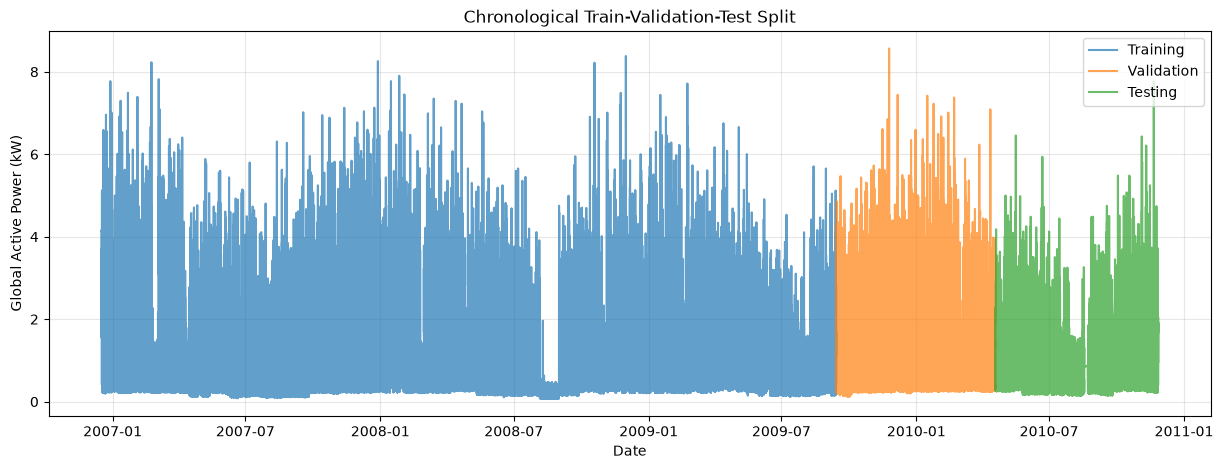

In [4]:
plt.figure(figsize=(15, 5))

plt.plot(train_df.index, train_df["Global_active_power"], label="Training", alpha=0.7)
plt.plot(val_df.index, val_df["Global_active_power"], label="Validation", alpha=0.7)
plt.plot(test_df.index, test_df["Global_active_power"], label="Testing", alpha=0.7)

plt.title("Chronological Train-Validation-Test Split")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
print("TRAINING")
print("Rows:", len(train_df))
print("Period:", train_df.index.min(), "to", train_df.index.max())

print("\nVALIDATION")
print("Rows:", len(val_df))
print("Period:", val_df.index.min(), "to", val_df.index.max())

print("\nTESTING")
print("Rows:", len(test_df))
print("Period:", test_df.index.min(), "to", test_df.index.max())

print("\nTotal rows:", len(train_df) + len(val_df) + len(test_df))

TRAINING
Rows: 95630
Period: 2006-12-16 17:30:00 to 2009-09-13 16:15:00

VALIDATION
Rows: 20492
Period: 2009-09-13 16:30:00 to 2010-04-18 17:30:00

TESTING
Rows: 20493
Period: 2010-04-18 17:45:00 to 2010-11-26 20:45:00

Total rows: 136615


In [8]:
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    gaps = data.index.to_series().diff()
    print(f"{name}: {(gaps > pd.Timedelta('15min')).sum()} internal gaps")

Training: 11 internal gaps
Validation: 2 internal gaps
Testing: 2 internal gaps


In [9]:
from sklearn.preprocessing import StandardScaler
import joblib

scaler = StandardScaler()

# Fit ONLY on training data
scaler.fit(train_df)

# Transform all three partitions using training statistics
train_scaled = pd.DataFrame(
    scaler.transform(train_df),
    index=train_df.index,
    columns=train_df.columns
)

val_scaled = pd.DataFrame(
    scaler.transform(val_df),
    index=val_df.index,
    columns=val_df.columns
)

test_scaled = pd.DataFrame(
    scaler.transform(test_df),
    index=test_df.index,
    columns=test_df.columns
)

print("Training scaled:", train_scaled.shape)
print("Validation scaled:", val_scaled.shape)
print("Testing scaled:", test_scaled.shape)

Training scaled: (95630, 7)
Validation scaled: (20492, 7)
Testing scaled: (20493, 7)


In [10]:
print("Training feature means:")
display(train_scaled.mean().round(4))

print("\nTraining feature standard deviations:")
display(train_scaled.std().round(4))

print("\nValidation feature means:")
display(val_scaled.mean().round(4))

Training feature means:


Global_active_power      0.0
Global_reactive_power   -0.0
Voltage                  0.0
Global_intensity         0.0
Sub_metering_1           0.0
Sub_metering_2           0.0
Sub_metering_3          -0.0
dtype: float64


Training feature standard deviations:


Global_active_power      1.0
Global_reactive_power    1.0
Voltage                  1.0
Global_intensity         1.0
Sub_metering_1           1.0
Sub_metering_2           1.0
Sub_metering_3           1.0
dtype: float64


Validation feature means:


Global_active_power      0.1599
Global_reactive_power    0.0527
Voltage                  0.5659
Global_intensity         0.1405
Sub_metering_1           0.0065
Sub_metering_2          -0.0217
Sub_metering_3           0.2927
dtype: float64

In [11]:
ARTIFACT_PATH = PROJECT_ROOT / "artifacts"
ARTIFACT_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(scaler, ARTIFACT_PATH / "scaler.pkl")

train_scaled.to_csv(PROCESSED_PATH / "train_scaled.csv")
val_scaled.to_csv(PROCESSED_PATH / "validation_scaled.csv")
test_scaled.to_csv(PROCESSED_PATH / "test_scaled.csv")

print("Scaler and scaled datasets saved successfully.")

Scaler and scaled datasets saved successfully.


In [13]:
WINDOW_SIZE = 96
TARGET_COLUMN = "Global_active_power"

def create_sequences(data, window_size=96):
    X, y, persistence, target_times = [], [], [], []

    target_idx = data.columns.get_loc(TARGET_COLUMN)

    # Identify continuous 15-minute segments
    gaps = data.index.to_series().diff()
    segment_ids = (gaps != pd.Timedelta("15min")).cumsum()

    for _, segment in data.groupby(segment_ids):

        values = segment.to_numpy(dtype=np.float32)

        # A segment must contain at least 97 readings
        if len(values) <= window_size:
            continue

        for i in range(window_size, len(values)):
            X.append(values[i-window_size:i])
            y.append(values[i, target_idx])

            # Persistence baseline: next value = last observed value
            persistence.append(values[i-1, target_idx])

            target_times.append(segment.index[i])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        np.asarray(persistence, dtype=np.float32),
        np.asarray(target_times)
    )

In [14]:
X_train, y_train, base_train, time_train = create_sequences(train_scaled)

X_val, y_val, base_val, time_val = create_sequences(val_scaled)

X_test, y_test, base_test, time_test = create_sequences(test_scaled)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (94478, 96, 7) (94478,)
Validation: (20204, 96, 7) (20204,)
Testing: (20205, 96, 7) (20205,)


In [15]:
print("Training input:", X_train.shape)
print("Validation input:", X_val.shape)
print("Testing input:", X_test.shape)

print("\nTarget timestamps:")
print("Training:", time_train[0], "to", time_train[-1])
print("Validation:", time_val[0], "to", time_val[-1])
print("Testing:", time_test[0], "to", time_test[-1])

assert X_train.shape[1:] == (96, 7)
assert X_val.shape[1:] == (96, 7)
assert X_test.shape[1:] == (96, 7)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("\nAll sequence checks passed.")

Training input: (94478, 96, 7)
Validation input: (20204, 96, 7)
Testing input: (20205, 96, 7)

Target timestamps:
Training: 2006-12-17 17:30:00 to 2009-09-13 16:15:00
Validation: 2009-09-14 16:30:00 to 2010-04-18 17:30:00
Testing: 2010-04-19 17:45:00 to 2010-11-26 20:45:00

All sequence checks passed.


In [16]:
SEQUENCE_PATH = ARTIFACT_PATH / "sequences"
SEQUENCE_PATH.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    SEQUENCE_PATH / "train_sequences.npz",
    X=X_train, y=y_train,
    baseline=base_train, timestamps=time_train
)

np.savez_compressed(
    SEQUENCE_PATH / "validation_sequences.npz",
    X=X_val, y=y_val,
    baseline=base_val, timestamps=time_val
)

np.savez_compressed(
    SEQUENCE_PATH / "test_sequences.npz",
    X=X_test, y=y_test,
    baseline=base_test, timestamps=time_test
)

print("All sequence datasets saved.")

All sequence datasets saved.


In [17]:
for name, X, y, baseline, timestamps in [
    ("TRAIN", X_train, y_train, base_train, time_train),
    ("VALIDATION", X_val, y_val, base_val, time_val),
    ("TEST", X_test, y_test, base_test, time_test)
]:
    print(f"\n{name}")
    print("Input shape:", X.shape)
    print("Target shape:", y.shape)
    print("Baseline shape:", baseline.shape)
    print("First target:", timestamps[0] if len(timestamps) else "No sequences")
    print("Last target:", timestamps[-1] if len(timestamps) else "No sequences")


TRAIN
Input shape: (94478, 96, 7)
Target shape: (94478,)
Baseline shape: (94478,)
First target: 2006-12-17 17:30:00
Last target: 2009-09-13 16:15:00

VALIDATION
Input shape: (20204, 96, 7)
Target shape: (20204,)
Baseline shape: (20204,)
First target: 2009-09-14 16:30:00
Last target: 2010-04-18 17:30:00

TEST
Input shape: (20205, 96, 7)
Target shape: (20205,)
Baseline shape: (20205,)
First target: 2010-04-19 17:45:00
Last target: 2010-11-26 20:45:00
